# 01 - Exploratory Data Analysis (SYNTHETIC data)
**Goal:** understand distributions, missing values, outliers, segments and repayment trends *before* modelling.
**Reminder:** every number below describes the simulation. The simulator has *designed* effects (see docs/simulation_design.md),
so EDA here shows whether we can recover them, not real-world lending behaviour.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_access import load_tables
from src.analytics.common import setup, save_fig, save_results, banner
from src.modelling.features import loan_frame

setup(); banner()
t = load_tables()
df = loan_frame(t)
R, K = t["repayments"], t["collections"]
results = {}
print({k: v.shape for k, v in t.items()})

ALL DATA IN THIS PROJECT IS SYNTHETIC. Findings describe the simulation, not real lending.


[data] loaded from PostgreSQL (analytics schema)
{'customers': (16812, 8), 'customer_financial_profiles': (20263, 13), 'loans': (20131, 19), 'repayments': (232795, 12), 'collections': (229472, 12)}


## 1. Missing-value analysis
Missingness is reported per column. Missing income / credit score / age were *kept as NULL* by the ETL (never silently imputed).
We check whether missingness is related to default (if it were, the missing flag itself would carry signal).

                                missing_n  missing_pct
age                                 270.0         1.34
monthly_income                      243.0         1.21
credit_score                        243.0         1.21
credit_utilization_pct                0.0         0.00
employment_type                       0.0         0.00
employment_type (== 'Unknown')      297.0         1.48
                default_rate_missing_pct  default_rate_present_pct  n_missing
monthly_income                      9.30                      8.59      129.0
credit_score                        7.03                      8.62      128.0
age                                 8.44                      8.60      154.0


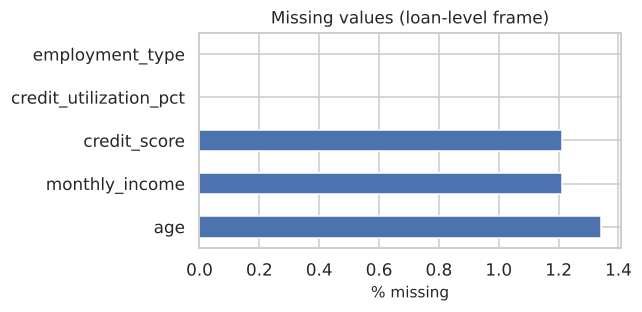

In [2]:
miss_cols = ["age", "monthly_income", "credit_score", "credit_utilization_pct", "employment_type"]
miss = pd.DataFrame({"missing_n": df[miss_cols].isna().sum(), "missing_pct": (df[miss_cols].isna().mean() * 100).round(2)})
miss.loc["employment_type (== 'Unknown')", :] = [(df.employment_type == "Unknown").sum(), round((df.employment_type == "Unknown").mean() * 100, 2)]
print(miss)
mature = df[df.months_on_book >= 15]
mm = {}
for c in ["monthly_income", "credit_score", "age"]:
    mm[c] = {"default_rate_missing_pct": round(100 * mature.loc[mature[c].isna(), "is_default"].mean(), 2),
             "default_rate_present_pct": round(100 * mature.loc[mature[c].notna(), "is_default"].mean(), 2),
             "n_missing": int(mature[c].isna().sum())}
print(pd.DataFrame(mm).T)
results["missing"] = {"table": miss.to_dict(), "default_rate_by_missingness": mm}

fig, ax = plt.subplots(figsize=(6, 3))
miss["missing_pct"].iloc[:5].plot.barh(ax=ax, color="#4c72b0"); ax.set_xlabel("% missing"); ax.set_title("Missing values (loan-level frame)")
save_fig(fig, "eda_missing")

## 2. Distributions of loan amount, income, interest rate
Money variables are right-skewed: the **mean exceeds the median**, so we report both and view the log scale.

                  count       mean        std      min        5%       25%  \
loan_amount     20131.0  149669.96  117514.94  10000.0  36000.00  71000.00   
monthly_income  19888.0   44206.55   24101.91  12000.0  16600.00  27500.00   
interest_rate   20131.0      16.89       3.75     10.0     10.46     14.23   
credit_score    19888.0     718.04      59.77    505.0    619.00    678.00   

                      50%        75%       95%        max  skew  
loan_amount     117000.00  189000.00  376000.0  1000000.0  2.27  
monthly_income   38900.00   54700.00   90365.0   366700.0  1.85  
interest_rate       16.81      19.43      23.3       31.5  0.21  
credit_score       718.00     758.00     817.0      900.0 -0.02  


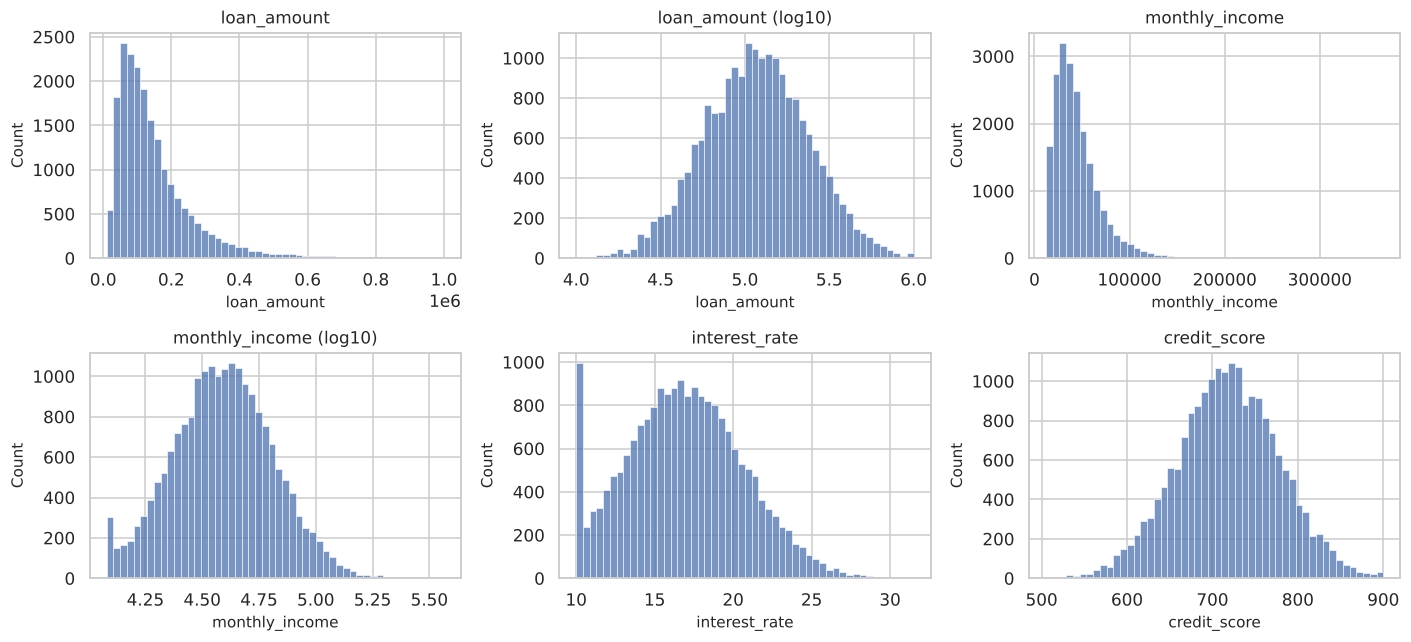

In [3]:
cols = ["loan_amount", "monthly_income", "interest_rate", "credit_score"]
desc = df[cols].describe(percentiles=[.05, .25, .5, .75, .95]).T
desc["skew"] = df[cols].skew()
print(desc.round(2))
results["distribution_summary"] = desc.round(3).to_dict()

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, (c, log) in zip(axes.ravel(), [("loan_amount", False), ("loan_amount", True), ("monthly_income", False),
                                       ("monthly_income", True), ("interest_rate", False), ("credit_score", False)]):
    x = np.log10(df[c].dropna()) if log else df[c].dropna()
    sns.histplot(x, bins=50, ax=ax, color="#4c72b0"); ax.set_title(f"{c}" + (" (log10)" if log else ""))
save_fig(fig, "eda_distributions")

## 3. Outlier analysis (IQR rule and z-score)
Outliers are **flagged, not removed**: very large loans/incomes are plausible. We check whether outliers behave differently.

                iqr_outliers   pct  default_rate_outliers_pct  \
loan_amount           1093.0  5.43                      19.42   
monthly_income         795.0  4.00                       5.41   
loan_to_income         723.0  3.64                      40.92   
foir                   546.0  2.75                      46.13   

                default_rate_non_outliers_pct  
loan_amount                              7.99  
monthly_income                           8.72  
loan_to_income                           7.30  
foir                                     7.52  


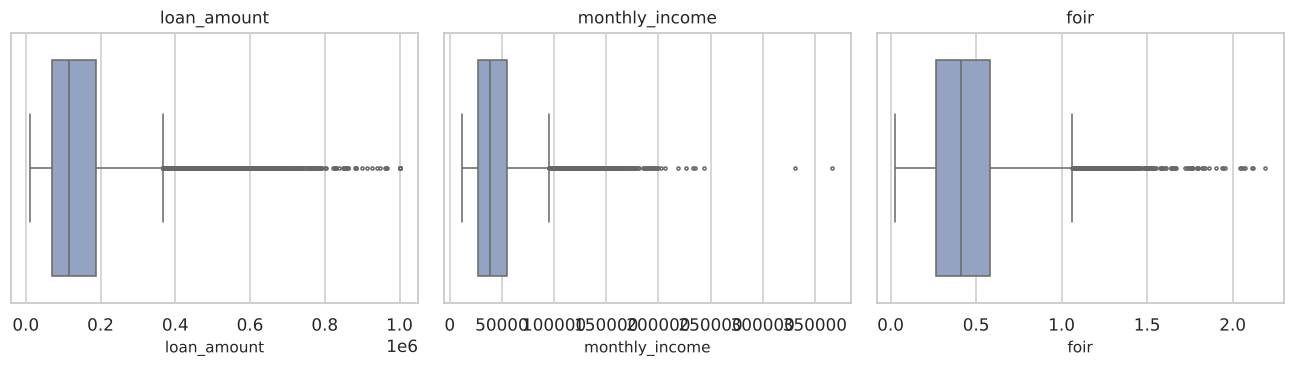

In [4]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

out = {}
for c in ["loan_amount", "monthly_income", "loan_to_income", "foir"]:
    s = df[c].dropna(); m = iqr_outliers(s)
    mat = df.loc[s.index][df.loc[s.index].months_on_book >= 15]
    mm_ = iqr_outliers(mat[c].dropna())
    out[c] = {"iqr_outliers": int(m.sum()), "pct": round(100 * m.mean(), 2),
              "default_rate_outliers_pct": round(100 * mat.loc[mm_[mm_].index, "is_default"].mean(), 2),
              "default_rate_non_outliers_pct": round(100 * mat.loc[mm_[~mm_].index, "is_default"].mean(), 2)}
print(pd.DataFrame(out).T)
results["outliers"] = out
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, c in zip(axes, ["loan_amount", "monthly_income", "foir"]):
    sns.boxplot(x=df[c], ax=ax, color="#8da0cb", fliersize=2); ax.set_title(c)
save_fig(fig, "eda_outliers")

## 4. Customer segmentation
Segments by employment type x city tier. Default rate uses **mature loans only** (>= 15 months on book): younger loans have not
had time to default (right-censoring), so including them would understate risk.

                 loans  default_rate  avg_loan  avg_income  avg_credit
employment_type                                                       
Gig Worker        1381          15.1   92105.0     23800.0       673.6
Contract Worker    770          11.8  114984.4     30300.0       691.9
Self-Employed     2084           9.9  138471.2     37900.0       709.8
Unknown            140           9.3  168071.4     39400.0       719.2
Business Owner    1003           7.6  224512.5     58700.0       718.2
Salaried          4986           5.9  158956.1     41900.0       736.3
city_tier        Tier 1  Tier 2  Tier 3
employment_type                        
Business Owner      6.9     7.6     8.6
Contract Worker     9.6    13.3    13.7
Gig Worker         13.7    14.1    18.5
Salaried            5.2     6.0     7.0
Self-Employed       9.3     9.3    11.9
Unknown             9.8    13.5     2.7


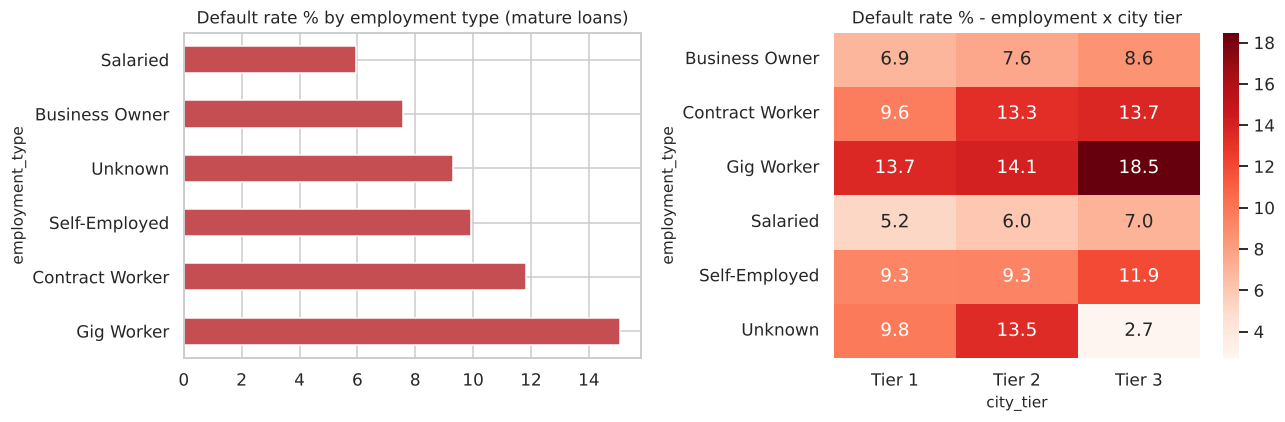

In [5]:
mature = df[df.months_on_book >= 15]
seg = (mature.groupby("employment_type").agg(loans=("loan_id", "count"), default_rate=("is_default", "mean"),
                                             avg_loan=("loan_amount", "mean"), avg_income=("monthly_income", "median"),
                                             avg_credit=("credit_score", "mean")).sort_values("default_rate", ascending=False))
seg["default_rate"] = (seg.default_rate * 100).round(2)
print(seg.round(1))
heat = mature.pivot_table(index="employment_type", columns="city_tier", values="is_default", aggfunc="mean") * 100
print(heat.round(1))
results["segments_by_employment"] = seg.round(2).to_dict()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
seg["default_rate"].plot.barh(ax=axes[0], color="#c44e52"); axes[0].set_title("Default rate % by employment type (mature loans)")
sns.heatmap(heat, annot=True, fmt=".1f", cmap="Reds", ax=axes[1]); axes[1].set_title("Default rate % - employment x city tier")
save_fig(fig, "eda_segments")

## 5. Relationships with default (univariate)
Default rate by decile of credit score, FOIR, and loan-to-income. A monotone pattern suggests a usable risk signal.

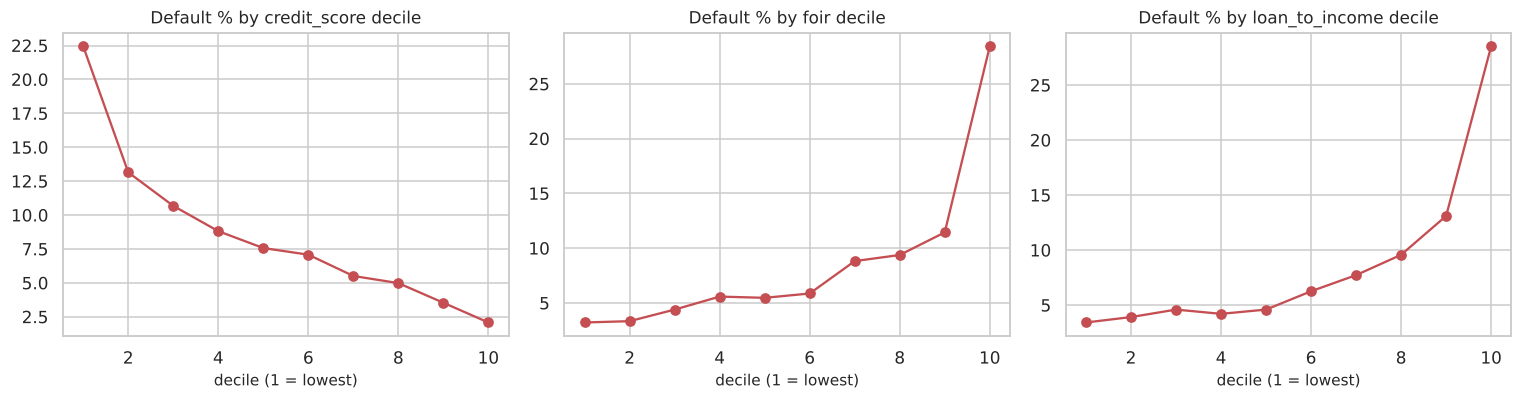

{'credit_score': [np.float64(22.44), np.float64(13.15), np.float64(10.68), np.float64(8.81), np.float64(7.57), np.float64(7.08), np.float64(5.51), np.float64(4.98), np.float64(3.53), np.float64(2.08)], 'foir': [np.float64(3.21), np.float64(3.33), np.float64(4.39), np.float64(5.58), np.float64(5.46), np.float64(5.86), np.float64(8.81), np.float64(9.38), np.float64(11.44), np.float64(28.42)], 'loan_to_income': [np.float64(3.42), np.float64(3.91), np.float64(4.59), np.float64(4.2), np.float64(4.59), np.float64(6.26), np.float64(7.72), np.float64(9.57), np.float64(13.1), np.float64(28.52)]}


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
dec = {}
for ax, c in zip(axes, ["credit_score", "foir", "loan_to_income"]):
    q = pd.qcut(mature[c], 10, duplicates="drop")
    r = mature.groupby(q, observed=True).is_default.mean() * 100
    dec[c] = [round(v, 2) for v in r.values]
    ax.plot(range(1, len(r) + 1), r.values, marker="o", color="#c44e52"); ax.set_title(f"Default % by {c} decile"); ax.set_xlabel("decile (1 = lowest)")
save_fig(fig, "eda_default_by_decile")
results["default_by_decile"] = dec
print(dec)

## 6. Repayment trends over time
Share of instalments not paid on the due date, by due month. **Caution:** the most recent months are biased - some late payers
have not paid *yet*, and the portfolio mix changes (more young loans). So we also look at *cohort* views (Section 7).

            installments  late_pct  unpaid_pct
due_month                                     
2025-11-01         10560     23.65        6.59
2025-12-01         11004     24.23        6.72
2026-01-01         11278     24.71        7.17
2026-02-01         11576     24.78        7.21
2026-03-01         11968     25.51        7.38
2026-04-01         12315     25.33        7.58
2026-05-01         11742     26.04        8.44
2026-06-01         10642     26.47       12.44


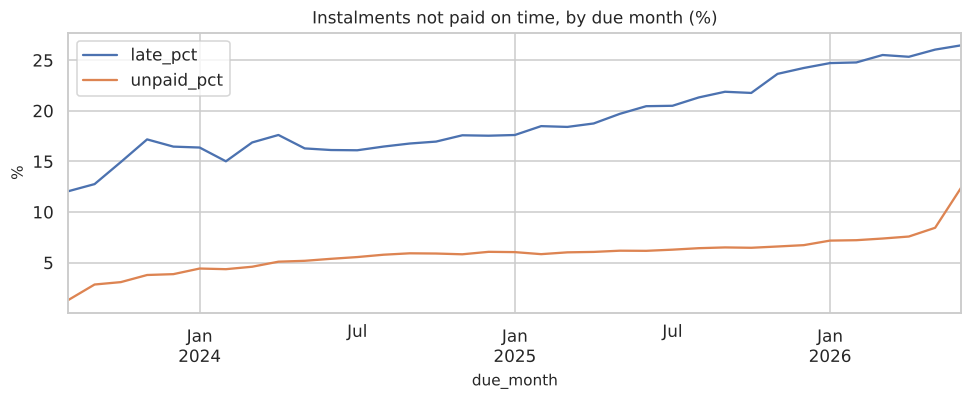

In [7]:
R2 = R.assign(late=(R.dpd > 0).astype(int), unpaid=R.repayment_status.isin(["UNPAID", "PARTIAL"]).astype(int))
trend = R2.groupby("due_month").agg(installments=("late", "size"), late_pct=("late", "mean"), unpaid_pct=("unpaid", "mean"))
trend[["late_pct", "unpaid_pct"]] *= 100
print(trend.round(2).tail(8))
fig, ax = plt.subplots(figsize=(9, 3.8))
trend[["late_pct", "unpaid_pct"]].plot(ax=ax); ax.set_title("Instalments not paid on time, by due month (%)"); ax.set_ylabel("%")
save_fig(fig, "eda_repayment_trend")
results["repayment_trend_last6"] = trend.tail(6).round(2).reset_index().astype({"due_month": str}).to_dict("records")

## 7. Cohort view - does newer vintage perform worse *at the same age*?
We compare the % of loans with a 30+ DPD instalment among the **first 6 instalments**, for cohorts old enough to have all 6 observed.

                    loans  pct_30dpd_first6
disbursement_month                         
2023-07-01            308              9.74
2023-10-01            409             10.27
2024-01-01            413             13.08
2024-04-01            452             10.40
2024-07-01            494              9.92
2024-10-01            617             12.64
2025-01-01            671             12.82
2025-04-01            702             12.68
2025-07-01            781             14.08
2025-10-01            938             13.65


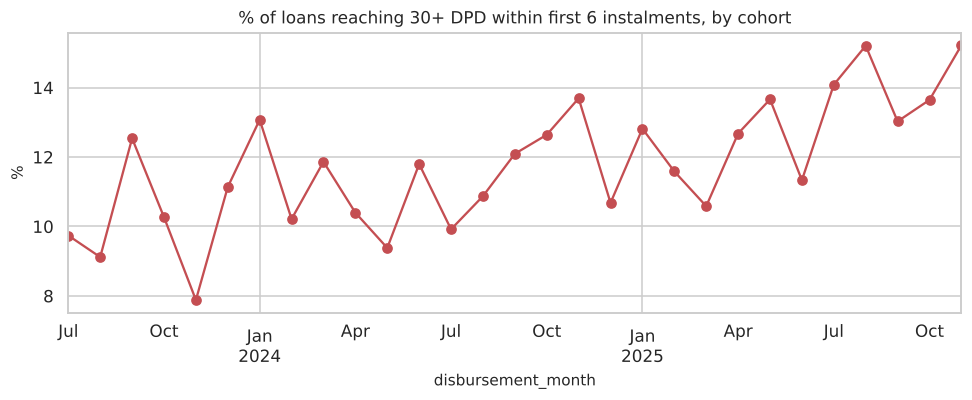

In [8]:
first6 = R[R.installment_no <= 6].groupby("loan_id").dpd.max().rename("max_dpd_first6")
c7 = df[df.months_on_book >= 7].merge(first6, left_on="loan_id", right_index=True)
c7["hit30"] = (c7.max_dpd_first6 >= 30).astype(int)
cohort = c7.groupby("disbursement_month").agg(loans=("loan_id", "count"), pct_30dpd_first6=("hit30", "mean"))
cohort["pct_30dpd_first6"] *= 100
print(cohort.round(2).iloc[::3])
fig, ax = plt.subplots(figsize=(9, 3.8))
cohort["pct_30dpd_first6"].plot(marker="o", ax=ax, color="#c44e52"); ax.set_title("% of loans reaching 30+ DPD within first 6 instalments, by cohort"); ax.set_ylabel("%")
save_fig(fig, "eda_cohort_30dpd_first6")
results["cohort_30dpd_first6"] = cohort.round(2).reset_index().astype({"disbursement_month": str}).to_dict("records")

## 8. Collections overview

In [9]:
cases = K.groupby(["loan_id", "installment_no"]).agg(due=("amount_due", "max"), rec=("amount_recovered", "sum"), max_dpd=("dpd_at_action", "max"))
cases["bucket"] = pd.cut(cases.max_dpd, [0, 29, 59, 89, 1e9], labels=["1-29", "30-59", "60-89", "90+"])
rec = cases.groupby("bucket", observed=True).agg(cases=("due", "size"), due=("due", "sum"), rec=("rec", "sum"))
rec["recovery_rate_pct"] = (100 * rec.rec / rec.due).round(2)
print(rec)
results["collections_recovery_by_dpd_bucket"] = rec.reset_index().astype({"bucket": str}).to_dict("records")
save_results("eda", results)

        cases           due           rec  recovery_rate_pct
bucket                                                      
1-29    33932  4.446002e+08  4.254011e+08              95.68
30-59    1951  2.599054e+07  1.275604e+07              49.08
60-89    1348  1.780685e+07  5.048460e+06              28.35
90+     12520  1.926080e+08  5.491522e+06               2.85
[saved] reports/results/eda.json


PosixPath('/home/claude/FinSight/reports/results/eda.json')